All libraries imported successfully!
Dataset loaded successfully!
Number of rows: 1372
Number of columns: 5
Column Names:
Index(['Variance', 'Skewness', 'Curtosis', 'Entropy', 'Class'], dtype='object')
Missing values in each column:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64
Number of duplicate records: 24
Class Distribution:
Class
0    762
1    610
Name: count, dtype: int64
Class Percentages:
Class
0    55.539359
1    44.460641
Name: proportion, dtype: float64


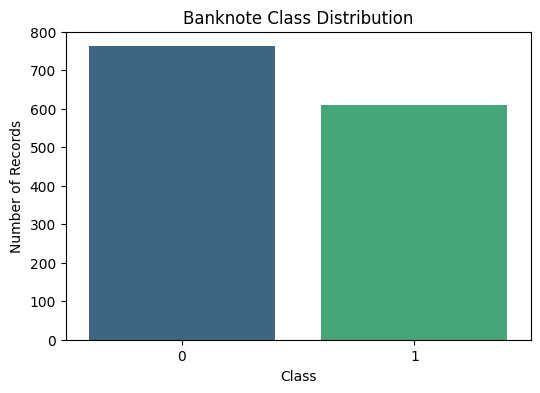

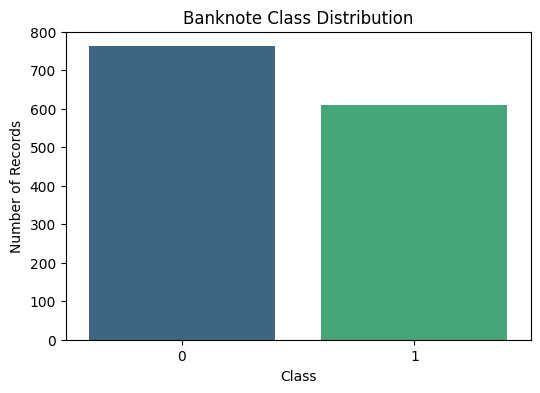

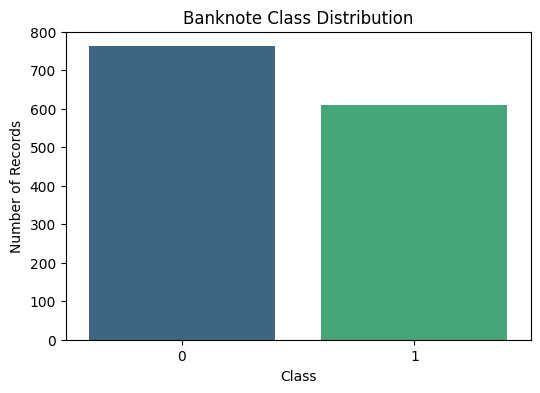

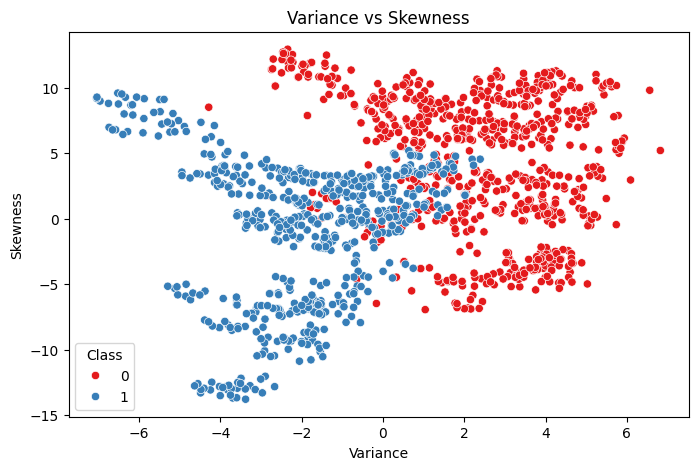

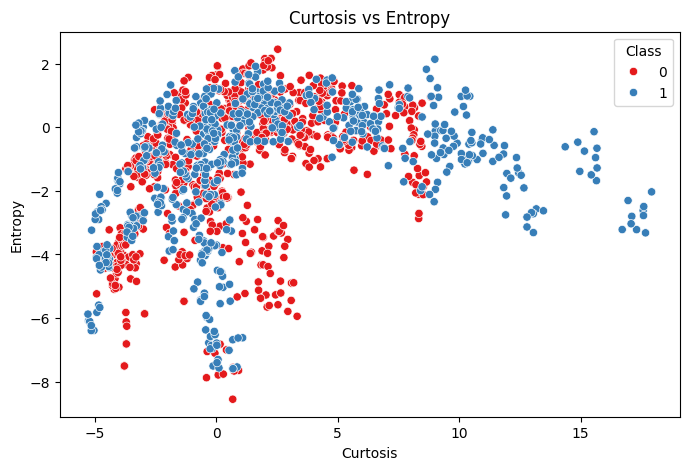

Input Features (X):
   Variance  Skewness  Curtosis  Entropy
0   3.62160    8.6661   -2.8073 -0.44699
1   4.54590    8.1674   -2.4586 -1.46210
2   3.86600   -2.6383    1.9242  0.10645
3   3.45660    9.5228   -4.0112 -3.59440
4   0.32924   -4.4552    4.5718 -0.98880

Target Variable (y):
0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64
Shape of X: (1372, 4)
Shape of y: (1372,)
Number of input features: 4
Training and Testing Data Split Successfully!
X_train shape: (1097, 4)
X_test shape: (275, 4)
y_train shape: (1097,)
y_test shape: (275,)
Feature Scaling Completed Successfully!
Scaled Training Data Shape: (1097, 4)
Scaled Testing Data Shape: (275, 4)
Logistic Regression Model Trained Successfully!
Model Parameters:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 

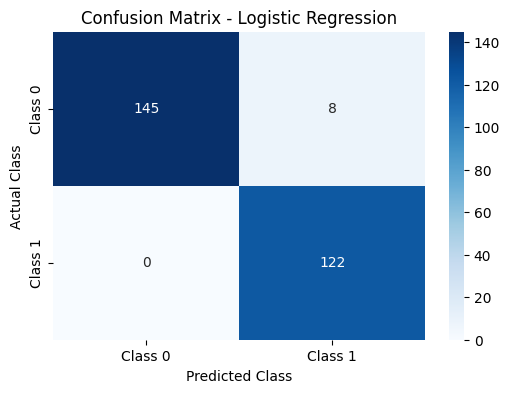

True Negative (TN): 145
False Positive (FP): 8
False Negative (FN): 0
True Positive (TP): 122


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columns = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


print("Column Names:")
print(df.columns)

df.dtypes

print("Missing values in each column:")
print(df.isnull().sum())

print("Number of duplicate records:", df.duplicated().sum())

df.describe()

class_counts = df["Class"].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

print("Class Percentages:")
print(class_percentages)

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Class", hue="Class", palette="viridis", legend=False)

plt.title("Banknote Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.show()

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Class", hue="Class", palette="viridis", legend=False)

plt.title("Banknote Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.show()



plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Class", hue="Class", palette="viridis", legend=False)

plt.title("Banknote Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.show()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Variance",
    y="Skewness",
    hue="Class",
    palette="Set1"
)

plt.title("Variance vs Skewness")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.legend(title="Class")
plt.show()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Curtosis",
    y="Entropy",
    hue="Class",
    palette="Set1"
)

plt.title("Curtosis vs Entropy")
plt.xlabel("Curtosis")
plt.ylabel("Entropy")
plt.legend(title="Class")
plt.show()


X = df[["Variance", "Skewness", "Curtosis", "Entropy"]]

y = df["Class"]

print("Input Features (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())


print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

print("Number of input features:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and Testing Data Split Successfully!")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

print("Model Parameters:")
print(model.get_params())

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("First 15 predicted classes:")
print(y_pred[:15])

comparison = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred
})

print(comparison.head(15))

comparison["Result"] = np.where(
    comparison["Actual Class"] == comparison["Predicted Class"],
    "Correct",
    "Incorrect"
)

print(comparison.head(15))

y_prob = model.predict_proba(X_test_scaled)

print("First 10 predicted probabilities:")
print(y_prob[:10])

probability_results = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred,
    "Probability Class 0": y_prob[:, 0],
    "Probability Class 1": y_prob[:, 1]
})

probability_results.head(10)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=1)

recall = recall_score(y_test, y_pred, pos_label=1)

f1 = f1_score(y_test, y_pred, pos_label=1)

print("Model Evaluation Results")
print("------------------------")

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

print("Classification Report:")
print(classification_report(y_test, y_pred))


cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)



plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


TN, FP, FN, TP = cm.ravel()

print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)


Threshold: 0.3
Predicted Class 0: 145
Predicted Class 1: 130

Threshold: 0.5
Predicted Class 0: 145
Predicted Class 1: 130

Threshold: 0.7
Predicted Class 0: 152
Predicted Class 1: 123
Threshold Comparison Table:


,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.9709,0.9385,1.0,0.9683
1,0.5,0.9709,0.9385,1.0,0.9683
2,0.7,0.9964,0.9919,1.0,0.9959



Confusion Matrix for Threshold: 0.3
[[145   8]
 [  0 122]]

Confusion Matrix for Threshold: 0.5
[[145   8]
 [  0 122]]

Confusion Matrix for Threshold: 0.7
[[152   1]
 [  0 122]]


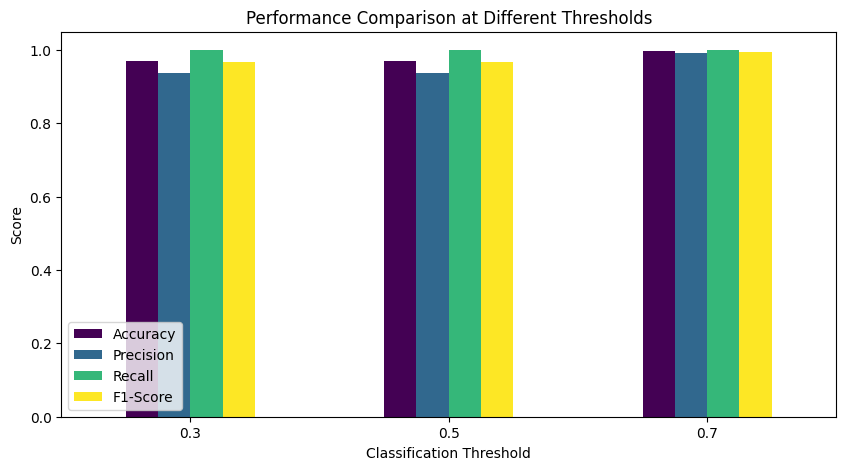

BANKNOTE AUTHENTICATION - LOGISTIC REGRESSION
----------------------------------------------
Total Records: 1372
Number of Features: 4
Training Records: 1097
Testing Records: 275

Model Evaluation:
Accuracy: 0.9709
Precision: 0.9385
Recall: 1.0
F1-Score: 0.9683

Model: Logistic Regression
Scaling: StandardScaler
Train-Test Split: 80:20
Random State: 42


In [ ]:


thresholds = [0.30, 0.50, 0.70]

threshold_predictions = {}

for threshold in thresholds:

    predictions = (y_prob[:, 1] >= threshold).astype(int)

    threshold_predictions[threshold] = predictions

    print("\nThreshold:", threshold)
    print("Predicted Class 0:", (predictions == 0).sum())
    print("Predicted Class 1:", (predictions == 1).sum())



threshold_results = []

for threshold in thresholds:

    predictions = threshold_predictions[threshold]

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

print("Threshold Comparison Table:")
display(threshold_df.round(4))

# Confusion matrices for different thresholds

for threshold in thresholds:

    predictions = threshold_predictions[threshold]

    cm_threshold = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    print("\nConfusion Matrix for Threshold:", threshold)
    print(cm_threshold)


threshold_df.set_index("Threshold")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 5), colormap="viridis")

plt.title("Performance Comparison at Different Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.show()

print("BANKNOTE AUTHENTICATION - LOGISTIC REGRESSION")
print("----------------------------------------------")

print("Total Records:", len(df))
print("Number of Features:", X.shape[1])
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModel Evaluation:")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))

print("\nModel:", "Logistic Regression")
print("Scaling:", "StandardScaler")
print("Train-Test Split:", "80:20")
print("Random State:", 42)
